## **Notebook B – Marché**

Ce document présente les analyses effectuées en vue d'établir le marché existant pour les locations courte durée à Amsterdam en vue d'établir une recommandation fiable (voir Notebook C et Note de décision).

### • Partie B1 – Création de variables

**• Créer au moins 5 variables**

In [1]:
# Importation des données
import pandas as pd
import numpy as np

listclean=pd.read_csv('listings_propre.csv')
revclean=pd.read_csv('reviews_propre.csv')

print(listclean.shape)
print(revclean.shape)

(10612, 29)
(552748, 5)


Nouvelles variables:

In [2]:
# Annonce active : dernière review publiée cette année (2026)
listclean['active'] = np.where(listclean['last_review'].str[:4] == '2026', True, False)

# Hôte multi-annonce (2 annonces ou plus)
listclean['multi_host'] = np.where(listclean['host_id'].duplicated(), True, False)

# Logement entier (oui/non)
listclean['entire_home'] = np.where(listclean['room_type']=='entire home/apt', True, False)

# Prix par personne (ratio 'price'/'accomodates')
listclean['price_pp'] = listclean['price']/listclean['accommodates']

# Ancienneté de l'hôte (en mois : on convertit les années en mois)
listclean['host_tenure'] = (listclean['hosts_time_as_host_years']*12)+listclean['hosts_time_as_host_months']

# Nombre d'équipements
listclean['Nb_amenities'] = listclean['amenities'].str.split(',').str.len()

# Durée minimale : variable non pertinente (pas de seuil réglementaire minimal à Amsterdam)
# Statut de la licence : déjà renseigné dans la variable 'statut_licence' créée dans le notebook A

print(listclean.head())

   number_of_reviews_ltm last_review  availability_365  \
0                      0  2024-05-18                17   
1                     14  2026-08-24               299   
2                      4  2026-08-09                 6   
3                      0  2025-08-10                 0   
4                      0  2022-09-11                 0   

   calculated_host_listings_count        room_type   price  accommodates  \
0                               1  entire home/apt  358.00           2.0   
1                               3     private room  485.00           4.0   
2                               1  entire home/apt  226.67           2.0   
3                               1  entire home/apt     NaN           4.0   
4                               1  entire home/apt     NaN           2.0   

   hosts_time_as_host_months  hosts_time_as_host_years  \
0                          4                         2   
1                          8                         6   
2                   

**• Définitions pour 'estimated_occupancy_l365d' (nuits occupées sur 12 mois) et 'estimated_revenue_l365d' (revenu sur 12 mois).**

'estimated_occupancy_l365d' correspond au taux d'occupation, soit une approximation du  nombre de nuits par an pour lesquelles le bien est occupé par un client :

$ \text{Taux d'occupation} = (\text{Nombre moyen de jours / réservation }) * (\text{Nombre de réservations du bien / an}) $

'estimated_revenue_l365d' correspond au revenu annuel, soit une approximation du revenu total engrangé par un bien immobilier sur une année :

$ \text{Revenu annuel} = \text{Prix de la nuitée} * \text{Taux d'occupation} $

### • Partie B2 – Combinaison des données

Agréger 'reviews' par annonce : nombre d’avis, date du dernier avis, avis des 12 derniers mois :

In [3]:
# 1. Définir la date de référence pour les 12 derniers mois : date de scrapping ('last_scraped' dans 'listings')
revclean['date'] = pd.to_datetime(revclean['date'])
date_ref = revclean['date'].max()
# Date de ref correspond à la date de scraping de 'listclean':
# listclean['last_scraped'][1]
time_difference = date_ref - pd.DateOffset(months=12)

rev_recent = revclean[revclean['date'] >= time_difference] # Sélectionner les 12 derniers mois

# 2. Grouper
group_global = revclean.groupby('listing_id', as_index=False).agg(
    nombre_avis=('id', 'count'), # Nombre total d'avis par annonce
    dernier_avis=('date', 'max') # Date du dernier avis
)

group_recent = rev_recent.groupby('listing_id', as_index=False).agg(
    avis_12_derniers_mois=('comments', lambda x: ' '.join(x.dropna().astype(str)))
) # Commentaires sur les 12 derniers mois

group = group_global.merge(group_recent, on='listing_id', how='left') # On fusionne les deux data frames

print(group.head())

   listing_id  nombre_avis dernier_avis  \
0       28871          812   2026-08-29   
1       29051          924   2026-08-29   
2       44391           42   2022-08-20   
3       48373            5   2024-04-28   
4       49552          663   2026-09-07   

                               avis_12_derniers_mois  
0  Nuestra estadía con Edwin fue placentera, el A...  
1  Very good Location for tourists close to the o...  
2                                                NaN  
3                                                NaN  
4  This place was in a great location.  <br/>We w...  


Joindre cette nouvelle table à 'listings' :

In [4]:
fulldata = listclean.merge(
    group,
    left_on='id',
    right_index=True,
    indicator=True,
    how='left' # Garder toutes les annonces de 'listings', même ceux qui n'ont pas d'avis dans 'reviews'
)

print(fulldata.head())

   number_of_reviews_ltm last_review  availability_365  \
0                      0  2024-05-18                17   
1                     14  2026-08-24               299   
2                      4  2026-08-09                 6   
3                      0  2025-08-10                 0   
4                      0  2022-09-11                 0   

   calculated_host_listings_count        room_type   price  accommodates  \
0                               1  entire home/apt  358.00           2.0   
1                               3     private room  485.00           4.0   
2                               1  entire home/apt  226.67           2.0   
3                               1  entire home/apt     NaN           4.0   
4                               1  entire home/apt     NaN           2.0   

   hosts_time_as_host_months  hosts_time_as_host_years  \
0                          4                         2   
1                          8                         6   
2                   

Nous avons choisi de garder l'ensemble des données : plutôt qu'un *inner join*, un *left join* permet de conserver l'ensemble des 10612 lignes de 'listclean'. Des données manquantes sont introduites dans les colonnes de 'revclean' fusionnées dans le jeu de données complet pour les biens listés qui n'ont pas de review documentée sur les 12 derniers mois.

La colonne '_merge' (produite par 'indicator = TRUE') permet de vérifier quelles observations présentent des reviews ('both') ou non ('left_only').

Sources permettant de rapporter l'offre totale à la population:

- La population totale de la ville d'Amsterdam est de 950787 habitants (estimation septembre 2026), disponible sur **le site de l'Institut Statistique National des Pays-Bas** (*Centraal Bureau voor de Statistiek*) :  
https://opendata.cbs.nl/#/CBS/nl/dataset/37230ned/table?searchKeywords=inkomen%20amsterdam
- Cette population est répartie de manière inégale, avec une concentration plus importante dans l'hypercentre qui décroit progressivement dans les quartiers qui en sont les plus éloignés (nous avons utilisé les 25 quartiers administratifs tels que listés sur le site de la municipalité).  
- Les quartiers les plus peuplés sont aussi globalement ceux qui présentent le plus grand nombre de logements et la plus grande proportion de logements dont les propriétaires sont des particuliers, comme visible dans le tableau ci-dessous.

In [5]:
from IPython.display import display

data = [
    (2026, "Oud-West, De Baarsjes", 71590, 40810, 15100),
    (2026, "De Pijp, Rivierenbuurt", 63980, 38995, 15950),
    (2026, "Oud-Zuid", 53306, 29531, 13040),
    (2026, "Slotervaart", 48770, 24549, 9390),
    (2026, "Centrum-Oost", 46498, 28167, 10045),
    (2026, "Geuzenveld, Slotermeer", 45913, 19822, 2345),
    (2026, "Centrum-West", 43905, 29688, 12820),
    (2026, "Indische Buurt, Oostelijk Havengebied", 42258, 22341, 5280),
    (2026, "Osdorp", 42071, 18911, 3710),
    (2026, "Westerpark", 41401, 24608, 6400),
    (2026, "Noord-West", 40204, 17173, 1155),
    (2026, "Watergraafsmeer", 40047, 21151, 7305),
    (2026, "Oud-Noord", 37604, 20788, 5755),
    (2026, "Bos en Lommer", 35563, 19061, 5360),
    (2026, "Oud-Oost", 35293, 19716, 3935),
    (2026, "Noord-Oost", 34705, 16302, 2855),
    (2026, "Gaasperdam", 32834, 15133, 1980),
    (2026, "IJburg, Zeeburgereiland", 32536, 15096, 4725),
    (2026, "Bijlmer-Oost", 30394, 13341, 2070),
    (2026, "Buitenveldert, Zuidas", 29109, 16388, 6905),
    (2026, "De Aker, Sloten, Nieuw-Sloten", 28903, 11637, 2960),
    (2026, "Weesp, Driemond", 27759, 11596, 1180),
    (2026, "Bijlmer-Centrum", 26710, 14069, 4815),
    (2026, "Bijlmer-West", 5447, 3466, 3010),
    (2026, "Sloterdijk Nieuw-West", 2954, 2092, 1425),
]

columns = ["Year", "Quartier", "Population", "Nb_logements", "Dont_particuliers"]
df = pd.DataFrame(data, columns=columns)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(df)

,Year,Quartier,Population,Nb_logements,Dont_particuliers
0,2026,"Oud-West, De Baarsjes",71590,40810,15100
1,2026,"De Pijp, Rivierenbuurt",63980,38995,15950
2,2026,Oud-Zuid,53306,29531,13040
3,2026,Slotervaart,48770,24549,9390
4,2026,Centrum-Oost,46498,28167,10045
5,2026,"Geuzenveld, Slotermeer",45913,19822,2345
6,2026,Centrum-West,43905,29688,12820
7,2026,"Indische Buurt, Oostelijk Havengebied",42258,22341,5280
8,2026,Osdorp,42071,18911,3710
9,2026,Westerpark,41401,24608,6400


Par ailleurs, le nombre de logements disponibles sur Airbnb tel que mesuré par la municipalité entre 2017 et 2022 (pas de données disponibles en dehors de cet intervalle de temps) a drastiquement diminué, en particulier entre 2021 et 2022 (disparition de plus de la moitié des annonces en un an), suite aux durcissements progressifs de la législation (voir partie A1) :

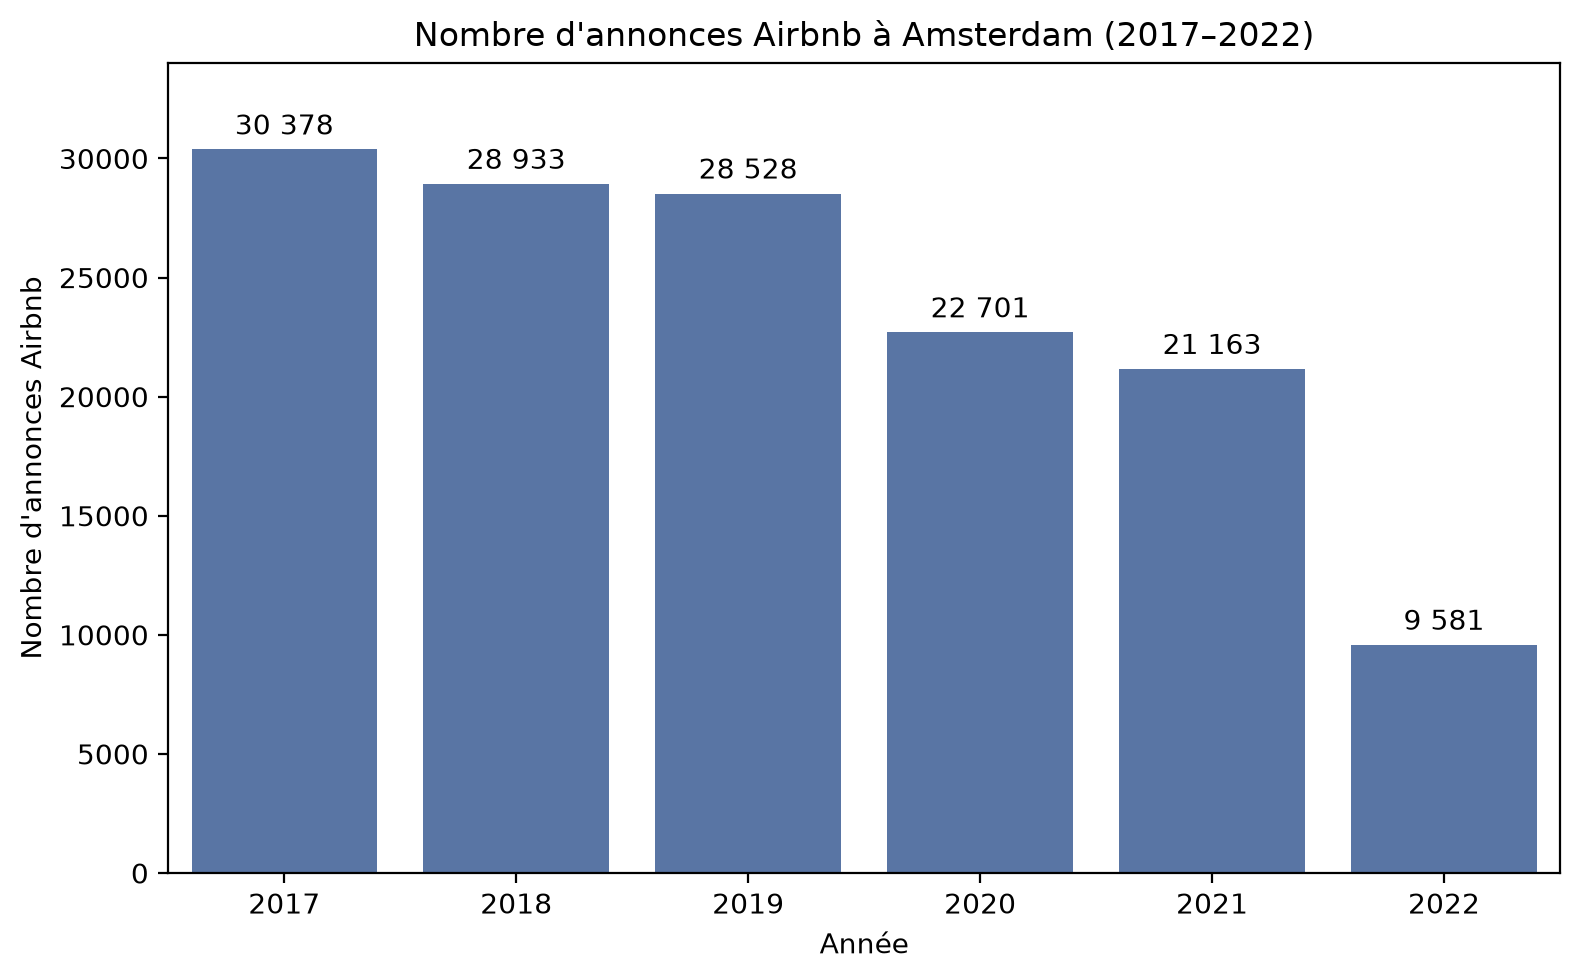

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Charger l'onglet 'data', filtrer sur 2017–2022 et trier par année
df = pd.read_excel("BHVESTAIRBNB-2019-gemeenten.xlsx", sheet_name="data")
df_plot = df[(df["Year"] >= 2017) & (df["Year"] <= 2022)].sort_values("Year")

# 2. Créer le barplot
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_plot, x="Year", y="Airbnb listings", color="#4C72B0", legend=False
)

# Ajouter les étiquettes de valeur au-dessus de chaque barre
for container in ax.containers:
    labels = [f"{int(bar.get_height()):,}".replace(",", " ") for bar in container]
    ax.bar_label(container, labels=labels, padding=3)

plt.ylim(0, df_plot["Airbnb listings"].max() * 1.12)
plt.title("Nombre d'annonces Airbnb à Amsterdam (2017–2022)")
plt.xlabel("Année")
plt.ylabel("Nombre d'annonces Airbnb")
plt.tight_layout()
plt.show()

Les données du tableau et du graphique ci-dessus proviennent toutes de **la section 'Recherche et statistique' (*Onderzoek en Statistiek*) du site de la ville d'Amsterdam**, consultable en anglais :  
https://onderzoek.amsterdam.nl/interactief/dashboard-kerncijfers?tab=indicator&thema=bevolking&indicator=BEVTOTAAL&indeling=ggwgebieden&jaar=2026&gebied=GA01&taal=en

### • Partie B3 – Réponses aux questions Q1 à Q4

#### Q1 – Taille et dynamique du marché

**• Nombre et part des annonces actives selon votre définition, et comment ce chiffre change avec une autre définition raisonnable**

In [7]:
nb_active = int(listclean['active'].sum()) # Nombre d'annonces actives
pct_active = round((nb_active/len(listclean['active']))*100, 2) # Pourcentage d'annonces actives
print("Nombre d'annonces actives :", nb_active)
print("Pourcentage d'annonces actives :", pct_active)

Nombre d'annonces actives : 6143
Pourcentage d'annonces actives : 57.89


In [8]:
# Avec une autre définition : on peut aussi utiliser 'availability_365' > 0
# (soit au moins une nuit de disponible dans l'année à venir)
nb_available = int((listclean['availability_365'] > 0).sum())
pct_available = round((nb_available/len(listclean['availability_365']))*100, 2)
print("Nombre d'annonces actives :", nb_available)
print("Pourcentage d'annonces actives :", pct_available)

Nombre d'annonces actives : 6152
Pourcentage d'annonces actives : 57.97


Les deux valeurs sont très proches (< 10 annonces d'écart) et correspondent à environ **58 %** du nombre total d'annonces.

On peut le comparer visuellement aux années précédentes :

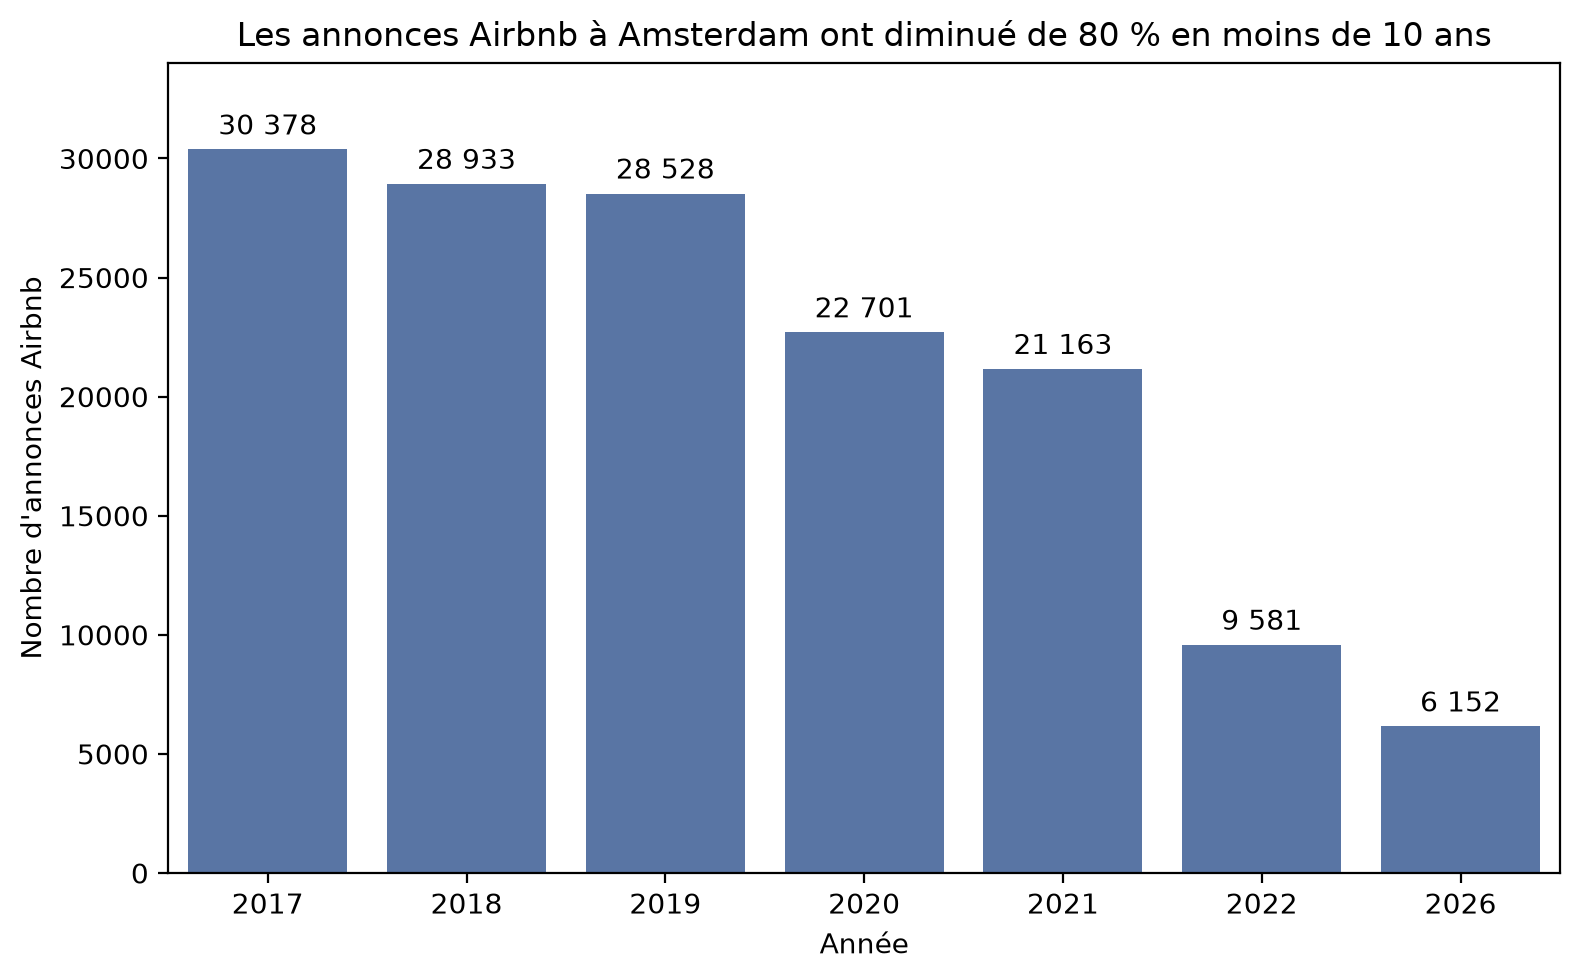

In [9]:
df.loc[len(df)] = [2026, 'gemeenten', 363, 'Amsterdam', 6152]
df_plot = df[(df["Year"] >= 2017) & (df["Year"] <= 2026)].sort_values("Year")

# 2. Créer le barplot
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_plot, x="Year", y="Airbnb listings", color="#4C72B0", legend=False
)

# Ajouter les étiquettes de valeur au-dessus de chaque barre
for container in ax.containers:
    labels = [f"{int(bar.get_height()):,}".replace(",", " ") for bar in container]
    ax.bar_label(container, labels=labels, padding=3)

plt.ylim(0, df_plot["Airbnb listings"].max() * 1.12)
plt.title("Les annonces Airbnb à Amsterdam ont diminué de 80 % en moins de 10 ans")
plt.xlabel("Année")
plt.ylabel("Nombre d'annonces Airbnb")
plt.tight_layout()
plt.show()

On constate que la baisse la plus drastique reste celle d'après 2021, qui correspond à la publication de l'étude de 2021 (van Haaren et al., 2021 – voir section A1), publiée par l'Union Européenne, qui montrait l'impact négatif d'Airbnb sur le coût et la qualité de la vie à Amsterdam et a entraîné la mise en place de nombreuses restrictions légales sur les locations de courte durée (voir A1). Depuis 2024, la législation s'est encore durcie, ce qui explique le chiffre encore plus faible pour l'année 2026.

**• Saisonnalité de l’activité (nombre d’avis par mois) : quels mois portent le revenu?**

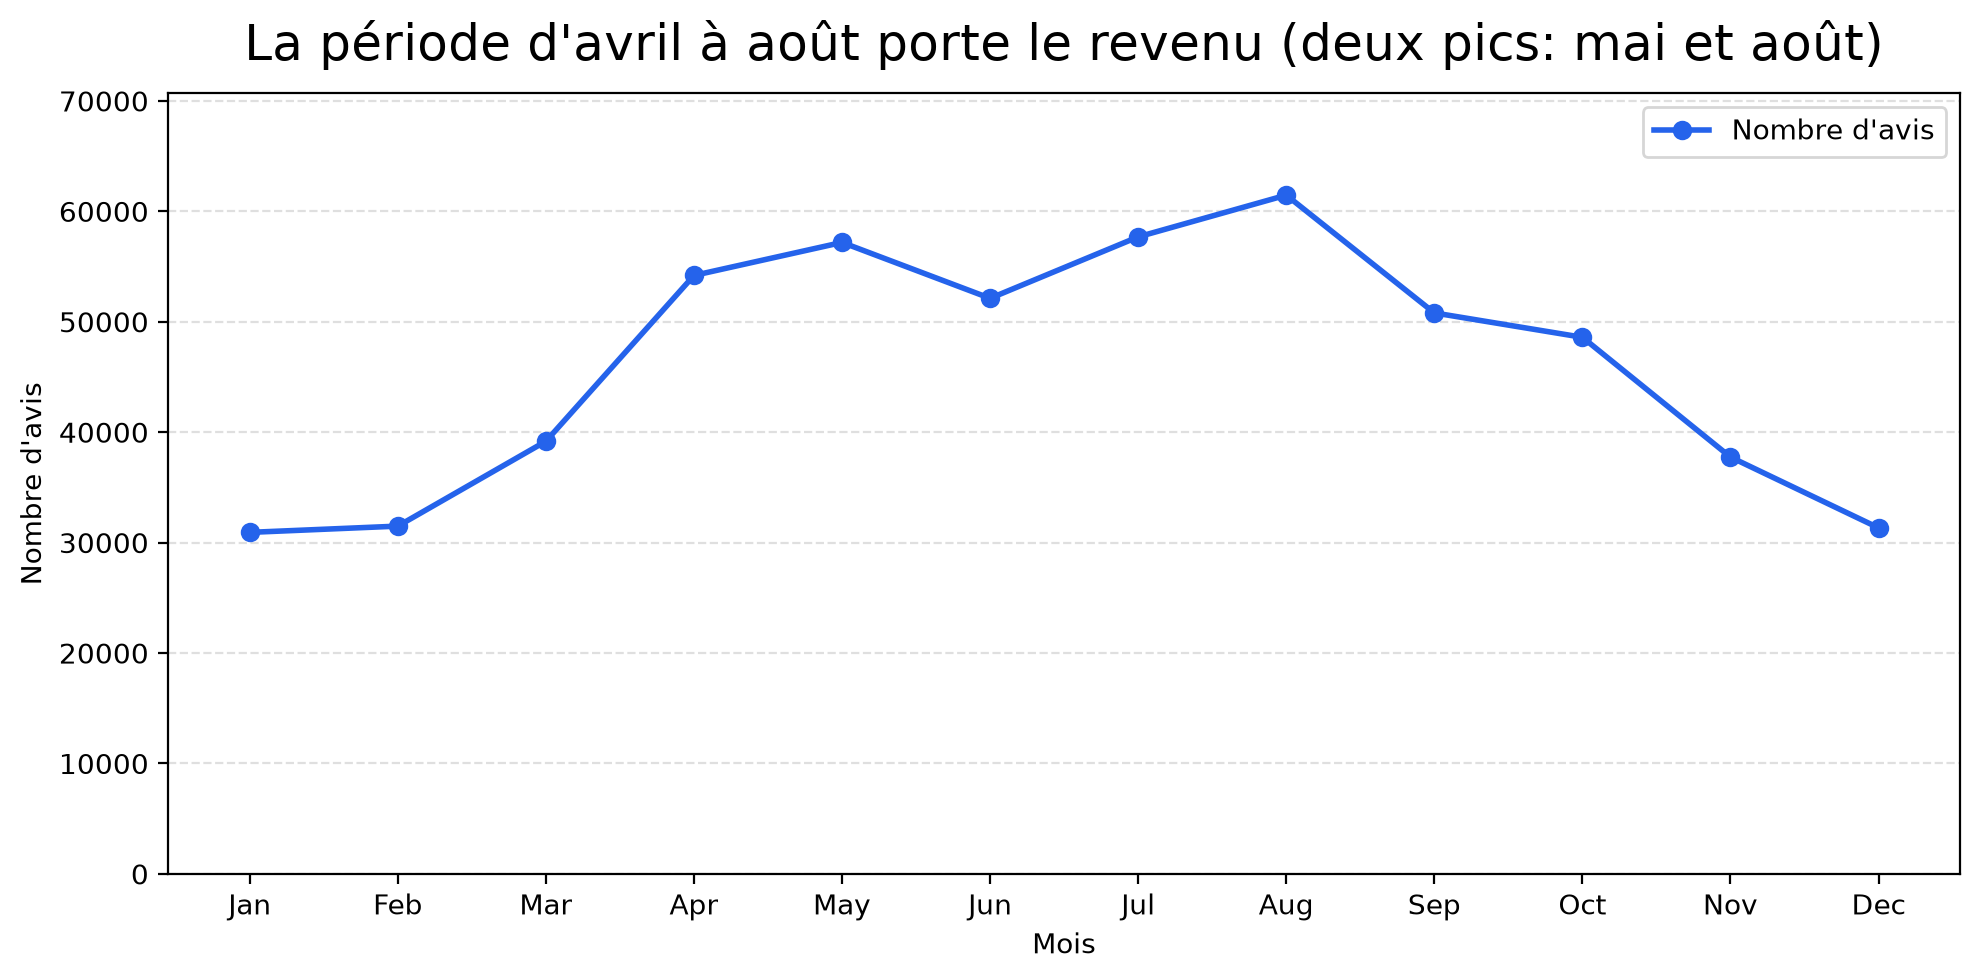

In [10]:
# On extrait le nombre d'avis par mois à partir de la colonne 'date' de 'revclean'
revclean['month'] = revclean['date'].dt.month

# Nombre total d'avis pour chaque mois
monthly_reviews = revclean.groupby('month').size().reset_index(name='review_count')

# Visualisation de la série temporelle
import matplotlib.dates as mdates
import calendar

## Convertir les nombres de 1 à 12 en noms des mois et les trier chronologiquement
monthly_reviews['month_label'] = monthly_reviews['month'].map(lambda m: calendar.month_abbr[int(m)])

order = [calendar.month_abbr[m] for m in range(1, 13)]
monthly_reviews['month_label'] = pd.Categorical(monthly_reviews['month_label'], categories=order, ordered=True)
monthly_reviews = monthly_reviews.sort_values('month_label')

## Graphique
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_reviews['month_label'],
    monthly_reviews['review_count'],
    marker="o",
    linewidth=2,
    color="#2563EB",
    label="Nombre d'avis",
)

## Commencer l'axe des ordonnées à 0 
ax.set_ylim(0, max(monthly_reviews['review_count']) * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.4)

## Titre et axes
ax.set_title("La période d'avril à août porte le revenu (deux pics: mai et août)", fontsize=18, pad=12)
ax.set_xlabel("Mois")
ax.set_ylabel("Nombre d'avis")
ax.legend()

plt.tight_layout()
plt.show()

Il faut nuancer ce résultat par un biais probable : un nombre important d'annonces (environ 38 % – nombre de lignes dans 'group' divisé par celui de 'listclean') n'ont pas d'avis disponibles dans le jeu de données. Le nombre de nuitées réellement réservées par mois serait donc sans doute assez différent de ce graphique, et potentiellement plus informatif.

#### Q2 – Concurrence



**• Part des annonces et du revenu estimé détenue par les hôtes multi-annonces**

On extrait les lignes correspondant à des hôtes multi-annonces pour estimer leur part de marché :

In [11]:
# Part des annonces
multihost_pct = round(int(fulldata['multi_host'].sum())/len(fulldata)*100, 2)

# Part du revenu
multihost_rev = fulldata.loc[fulldata['multi_host'] == True, 'estimated_revenue_l365d'].sum()
multihost_pctrev = round(multihost_rev/fulldata['estimated_revenue_l365d'].sum()*100, 2)

print("Les hôtes multi-annonces représentent", multihost_pct, "% des annonces et", multihost_pctrev, "% du revenu total.")

Les hôtes multi-annonces représentent 13.01 % des annonces et 26.21 % du revenu total.


Ces chiffres sont très faibles par rapport à la moyenne mondiale (62,9 % des annonces, voir [ici](https://insideairbnb.com/fr/report/the-threat-of-short-term-rentals-to-housing/)), ce qui était attendu au vu de l'interdiction de louer sa résidence secondaire à Amsterdam.

**• Part détenue par les 10 % d’hôtes les plus actifs**

On commence par compter les hôtes les plus actifs et extraire le décile supérieur de la distribution.

In [12]:
from collections import Counter
import math

mostactive = Counter(fulldata['host_id'])
n_top = max(1, math.ceil(len(mostactive) * 0.10))

top_10_pct = mostactive.most_common(n_top)
print("Il y a", len(top_10_pct), "hôtes représentant les 10% les plus actifs du total de", len(mostactive), "hôtes.")

Il y a 924 hôtes représentant les 10% les plus actifs du total de 9231 hôtes.


In [13]:
# Part de marché détenue par ces 10 %

top_ids = [pair[0] for pair in top_10_pct] # Extraction de l'ID des hôtes

matched_mask = fulldata['host_id'].isin(top_ids) # Match des ID des deux data frames

## Pour le nombre d'annonces :
top_sum = fulldata.loc[matched_mask, 'host_id'].count() # Compte des annonces des 10%
total_sum = fulldata['host_id'].count() # Compte du nombre total d'annonces

share_proportion = round(top_sum / total_sum, 2)
share_percent = round((top_sum / total_sum) * 100, 2)

## Pour le revenu :
top_rev = fulldata.loc[matched_mask, 'estimated_revenue_l365d'].sum() # Revenu des 10%
total_rev = fulldata['estimated_revenue_l365d'].sum() # Revenu total du jeu de données

rev_prop = round(top_rev / total_rev, 2)
rev_percent = round((top_rev / total_rev) * 100, 2)

print("Les 10 % d'hôtes les plus actifs cumulent", share_percent, "% des annonces et", rev_percent, "% du revenu total.")

Les 10 % d'hôtes les plus actifs cumulent 21.72 % des annonces et 39.86 % du revenu total.


10 % des hôtes représentent 40 % du revenu : on a bien une concentration du marché dans une minorité d'utilisateurs multi-annonces de la plateforme à Amsterdam.

**• Courbe de Lorenz et indice de Gini du revenu par hôte**

Indice de Gini : 0.83


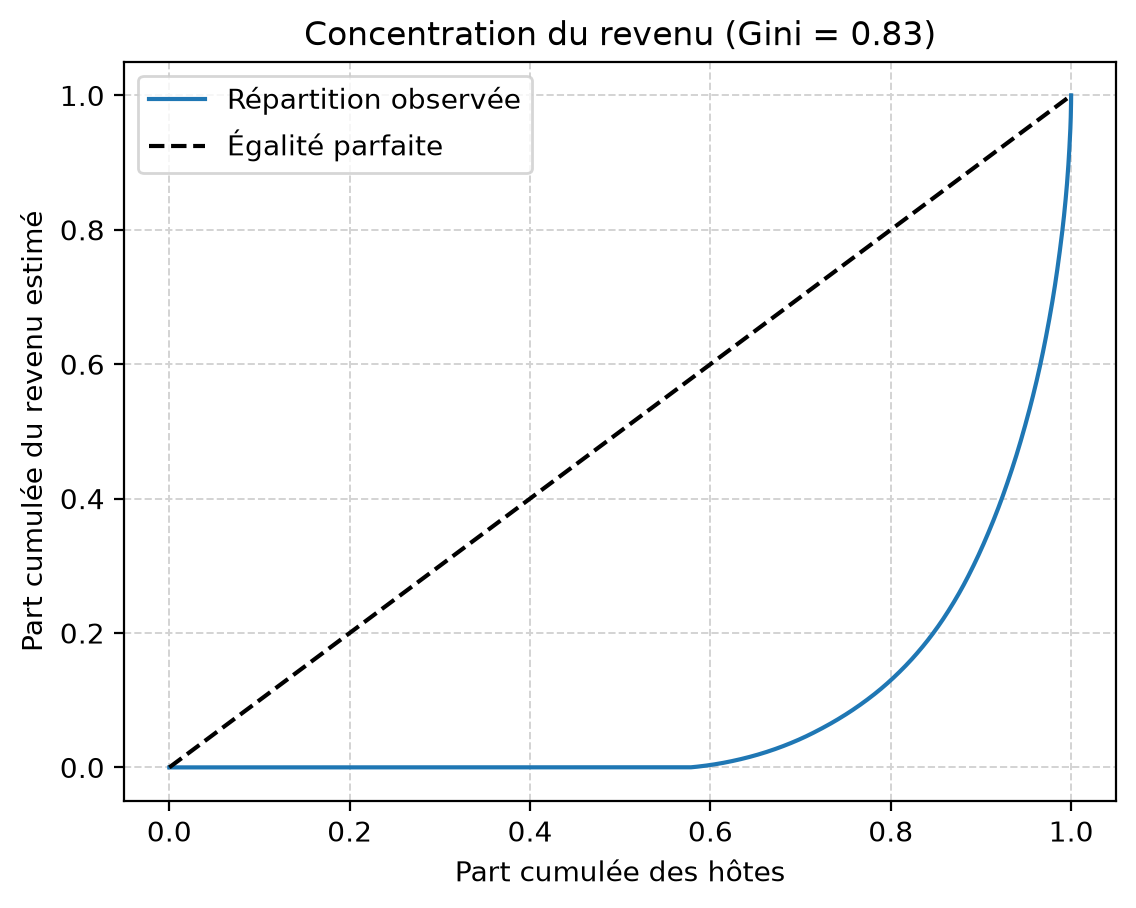

In [14]:
revenu_par_hote = fulldata.groupby("host_id")["estimated_revenue_l365d"].sum()
revenus = np.sort(revenu_par_hote.values) # Du plus petit au plus grand

part_hotes = np.concatenate([[0], np.arange(1, len(revenus) + 1) / len(revenus)])
part_revenu = np.concatenate([[0], np.cumsum(revenus) / revenus.sum()])

gini = 1 - 2 * np.trapezoid(part_revenu, part_hotes) # np.trapz avec NumPy < 2
print(f"Indice de Gini : {gini:.2f}")

plt.plot(part_hotes, part_revenu, label="Répartition observée")
plt.plot([0, 1], [0, 1], linestyle="--", color="black", label="Égalité parfaite")
plt.grid(color='lightgrey', linestyle='--', linewidth=0.7)
plt.xlabel("Part cumulée des hôtes")
plt.ylabel("Part cumulée du revenu estimé")
plt.title(f"Concentration du revenu (Gini = {gini:.2f})")
plt.legend()
plt.show()

En accord avec le haut pourcentage de revenu contrôlé par les 10% d'hôtes les plus actifs, la répartition des revenus est **extrêmement inégalitaire** : environ 15 % des hôtes contrôlent 80 % du revenu total ! Il y a donc déjà une minorité d'hôtes à très hauts revenus qui contrôlent l'essentiel du marché.